# FXS / 02 — EURJPY: confirmation 2021–2025 of the frozen candidates

Protocols: [`001`](../../../discussions/FX_Intraday_Seasonality/001_claude_fxs01_preregistration.md) §5, [`002`](../../../discussions/FX_Intraday_Seasonality/002_claude_fxs01_amendment_per_pair.md). Reads `EURJPY/01/candidates_frozen.csv` unchanged (SHA-256 must match `EURJPY/01/summary.json`).

Each candidate is traded every day at quoted prices (long: buy ask at start, sell bid at end; short: sell bid, buy ask); commission 0.70 bp round trip.

| Gate | Condition |
|---|---|
| K1 | mean after spread > 0, NW one-sided p, BH across this pair's candidates, q ≤ 0.05 |
| K2 | net: block-bootstrap lower bound > 0 at blocks 10 and 20 |
| K3 | mean net at 2× commission > 0 |
| K4 | yearly mean net > 0 in ≥ 3 of 5 years |

In [1]:
PAIR = "EURJPY"

import json, os, sys, tempfile
import datetime as dt
from dataclasses import replace, asdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:                                   # never touch the real market-data folder in a smoke run
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs_")
    os.environ["FXS_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]
    os.environ.pop("DUKASCOPY_DIR", None)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F

cfg = F.FXSConfig()
if SYNTHETIC:
    cfg = replace(cfg, n_placebo=3, n_boot=2_000)
POOLED_T = F.bonferroni_t(F.pooled_n_tests(cfg))
HOURS = lambda clock, step: ([60 * h for h in range(0, 25, step)], [F.slot_label(clock, 60 * h).split()[1] for h in range(0, 25, step)])
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 120)
IN = Path.cwd() / ("01_synthetic" if SYNTHETIC else "01")
OUT = Path.cwd() / ("02_synthetic" if SYNTHETIC else "02"); OUT.mkdir(exist_ok=True)
START, END = F.CONFIRMATION
frozen = IN / "candidates_frozen.csv"
disc = json.loads((IN / "summary.json").read_text())
sha = disc["candidates_sha256"]
assert F.frozen_hash_ok(frozen, sha), "candidates_frozen.csv changed after discovery"
cand = pd.read_csv(frozen)
print(f"{PAIR}: {len(cand)} frozen candidates (sha256 {sha[:12]}...) | discovery D0 = {disc['D0']} | {START} -> {END}")
display(cand[["id", "clock", "start_time", "end_time", "direction", "mean_bps", "t", "pooled_bonferroni"]])

EURJPY: 2 frozen candidates (sha256 3ead39780c9d...) | discovery D0 = STRUCTURE_FOUND | 2021-01-01 -> 2025-12-31


,id,clock,start_time,end_time,direction,mean_bps,t,pooled_bonferroni
0,EURJPY-01,NY,NY 10:45,NY 11:00,-1,-1.194497,-4.146766,False
1,EURJPY-02,NY,NY 12:35,NY 16:35,1,1.836600,4.128380,False


## 1. Download complete? Confirmation panels

In [2]:
cov = F.file_coverage(PAIR, START, END)
print(f"{PAIR}: {cov['present']}/{cov['expected']} day files ({cov['share']:.2%})")
assert cov["share"] >= cfg.min_file_share, "download not complete for the confirmation window: wait and rerun"
panels = F.load_panels([PAIR], START, END, "confirmation", cfg) if len(cand) else {}
display(pd.DataFrame([{"clock": c, "days": len(v.dates), "median_spread_bps": float(np.median(v.spread_bps()))}
                      for (p, c), v in panels.items()]).round(3))

EURJPY: 1566/1566 day files (100.00%)


,clock,days,median_spread_bps
0,NY,1298,0.642
1,UTC,1298,0.645


## 2. Gates K1–K4

In [3]:
trades = {r["id"]: F.candidate_trades(panels[(PAIR, r["clock"])], int(r["start"]), int(r["end"]), int(r["direction"]), cfg)
          for _, r in cand.iterrows()}
res = pd.DataFrame()
if len(cand):
    res = cand[["id", "clock", "start_time", "end_time", "direction", "pooled_bonferroni"]].assign(
        disc_mean_bps=cand["mean_bps"]).merge(F.confirm(trades, cfg), on="id")
    display(res.drop(columns=["boot_net_lower"]).round(3))
    res.to_csv(OUT / "02_confirmation.csv", index=False)
    print(res["verdict"].value_counts().to_string())
else:
    print("no frozen candidates: nothing to confirm")

,id,clock,start_time,end_time,direction,pooled_bonferroni,disc_mean_bps,n_days,gross_bps,t,p_one_sided,net_bps,net2_bps,gross_pips,win_rate,years_net_positive,years,K1,q,K2,K3,K4,verdict
0,EURJPY-01,NY,NY 10:45,NY 11:00,-1,False,-1.194,1298,-0.859,-3.527,1.000,-1.559,-2.259,-1.312,0.418,0,5,False,1.000,False,False,False,NOT_CONFIRMED
1,EURJPY-02,NY,NY 12:35,NY 16:35,1,False,1.837,1298,0.808,1.737,0.041,0.108,-0.592,1.234,0.532,3,5,False,0.082,False,False,True,NOT_CONFIRMED


verdict
NOT_CONFIRMED    2


## 3. By year and cumulative net per candidate

One unit traded every confirmation day; cumulative net return in bps.

year,2021,2022,2023,2024,2025
EURJPY-01,-0.57,-2.69,-0.85,-1.89,-1.80
EURJPY-02,-0.61,0.74,0.44,-0.87,0.85


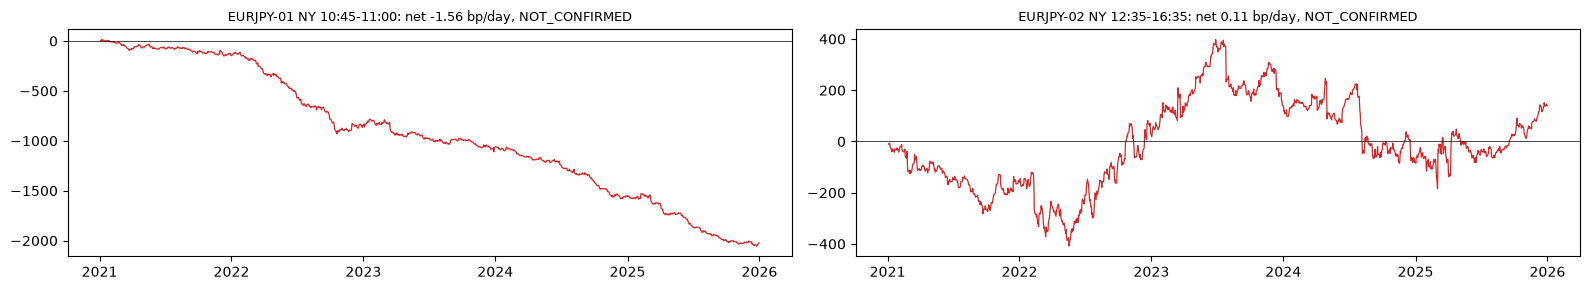

In [4]:
if len(res):
    yearly = pd.DataFrame({cid: tr.groupby("year")["net_bps"].mean() for cid, tr in trades.items()}).T
    display(yearly.round(2)); yearly.to_csv(OUT / "02_by_year_net.csv")
    n = len(res)
    fig, axes = plt.subplots(int(np.ceil(n / 2)), 2, figsize=(16, 3 * np.ceil(n / 2)), squeeze=False)
    for ax, (_, r) in zip(axes.flat, res.iterrows()):
        tr = trades[r["id"]]
        ax.plot(pd.to_datetime(tr["date"]), tr["net_bps"].cumsum(), lw=0.9, color="C2" if r["verdict"] == "CONFIRMED" else "C3")
        ax.axhline(0, color="black", lw=0.5)
        ax.set_title(f"{r['id']} {r['start_time']}-{r['end_time'].split()[1]}: net {r['net_bps']:.2f} bp/day, {r['verdict']}", fontsize=9)
    for ax in axes.flat[n:]:
        ax.axis("off")
    plt.tight_layout(); plt.savefig(OUT / "02_equity.png", dpi=110); plt.show()

## 4. Discovery vs confirmation

If the discovery means were mostly selection noise, the confirmation means collapse towards zero.

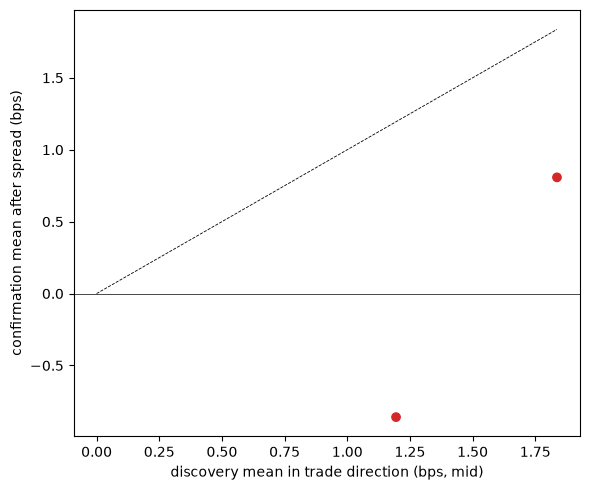

median ratio confirmation / discovery: -0.14


In [5]:
if len(res):
    disc_dir = res["direction"] * res["disc_mean_bps"]
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(disc_dir, res["gross_bps"], c=np.where(res["verdict"] == "CONFIRMED", "C2", "C3"))
    lim = max(1.0, float(np.nanmax(np.abs(disc_dir))))
    ax.plot([0, lim], [0, lim], "k--", lw=0.6); ax.axhline(0, color="black", lw=0.5)
    ax.set_xlabel("discovery mean in trade direction (bps, mid)"); ax.set_ylabel("confirmation mean after spread (bps)")
    plt.tight_layout(); plt.savefig(OUT / "02_shrinkage.png", dpi=110); plt.show()
    print("median ratio confirmation / discovery:", round(float(np.median(res["gross_bps"] / disc_dir)), 3))

In [6]:
summary = {"study": "FXS02", "pair": PAIR, "fxs_version": F.FXS_VERSION, "synthetic": SYNTHETIC,
           "window": [str(START), str(END)], "candidates_sha256": sha, "discovery_D0": disc["D0"], "n_candidates": int(len(cand)),
           "confirmed": res.loc[res["verdict"] == "CONFIRMED", "id"].tolist() if len(res) else [],
           "results": res.to_dict(orient="records") if len(res) else []}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps({k: summary[k] for k in ("pair", "discovery_D0", "n_candidates", "confirmed")}, indent=2))

{
  "pair": "EURJPY",
  "discovery_D0": "STRUCTURE_FOUND",
  "n_candidates": 2,
  "confirmed": []
}
